# Indigenous Wholistic Factors Project: Live Room Vote Demonstration

**This notebook runs on synthetic data, not real youth responses.** Every respondent here is simulated. The results show how the method behaves. They are not findings about Native American youth.

A room votes on which California Healthy Kids Survey (CHKS) factors belong in a model predicting past-year suicidal ideation. The room's top-voted items then go into a LASSO logistic regression, following the structure of the [IWFP notebook and Stata scripts](../scripts/primary_analysis.do) from:

Sierra VQ (2025). Predicting Suicidal Ideation Among Native American High Schoolers in California. *Archives of Suicide Research* 30(1):80-97. [PMC12424082](https://pmc.ncbi.nlm.nih.gov/articles/PMC12424082/)

| | In this notebook | In the published study |
|---|---|---|
| Data | Synthetic, 2,609 fake respondents calibrated to published totals | CHKS 2019-20, not shared |
| Who chose the predictors | The people in this room | Community partners and the study team |
| Software | Python, scikit-learn | Stata 17 |

**The saved copy on GitHub shows rehearsal votes.** To run it live, choose Run All.

## How to read this notebook

Three rules apply to every chart below:

1. **These are fake people.** Results show how the method behaves. They are not findings about Native American youth.
2. **"Goes with" isn't "causes."** The model finds patterns. It can't say why they exist.
3. **Kept isn't the same as important.** LASSO keeps what predicts best in this data, not what matters most for prevention.

Each result has a note. **In plain terms** says what to look at. **Go further** is a skill to take to your own results.

# Setup

In [1]:
%matplotlib inline
%config InlineBackend.figure_format = "retina"

import inspect
import os

import numpy as np
import pandas as pd
from IPython.display import Markdown, display

import figures as fig
import iwfp_reference as iwfp
import load_votes as lv
import pipeline as pl
import synthetic_data as sd

# The board to read. The saved copy on GitHub was run with IWFP_DEMO_BOARD=nov4-rehearsal.
BOARD_ID = os.environ.get("IWFP_DEMO_BOARD", "nov4-talk")
TOP_N = 30          # the room's top 30, ties kept. 0 = every item with a vote.

# Leave as None for live votes. Set to a file to use it instead:
#   "paper_tally.csv"        a copy of paper_tally_template.csv with the sticky-dot counts typed in
#   "rehearsal_votes.csv"    rehearsal votes (tell the room these aren't theirs)
RESULTS_CSV = None

pd.set_option("display.max_rows", 120, "display.max_colwidth", 70)

# Votes from the room

Votes load first and are saved to `results/` straight away.

In [2]:
votes, source = lv.load_votes(BOARD_ID, RESULTS_CSV)
ranked, ties_extended = lv.top_voted(votes, TOP_N)
candidates = ranked["item_id"].tolist()
labels = lv.LABELS

display(Markdown(f"**{source}**"))
print(f"{votes['vote_count'].sum()} dots on {(votes['vote_count'] > 0).sum()} of {len(votes)} items.")
print(f"{len(candidates)} items go into the model."
      + (f" Ties at #{TOP_N} were kept." if ties_extended else ""))

**REHEARSAL VOTES, not this room's. Live votes from board 'nov4-rehearsal'. Saved to results/.**

37 dots on 29 of 84 items.
29 items go into the model.


**In plain terms:** longer bars mean more dots. This shows what the room valued. It doesn't yet say anything about what predicts.

**Go further:** keep this chart in mind. The model answers a different question from the one the room just answered, so the two may disagree.

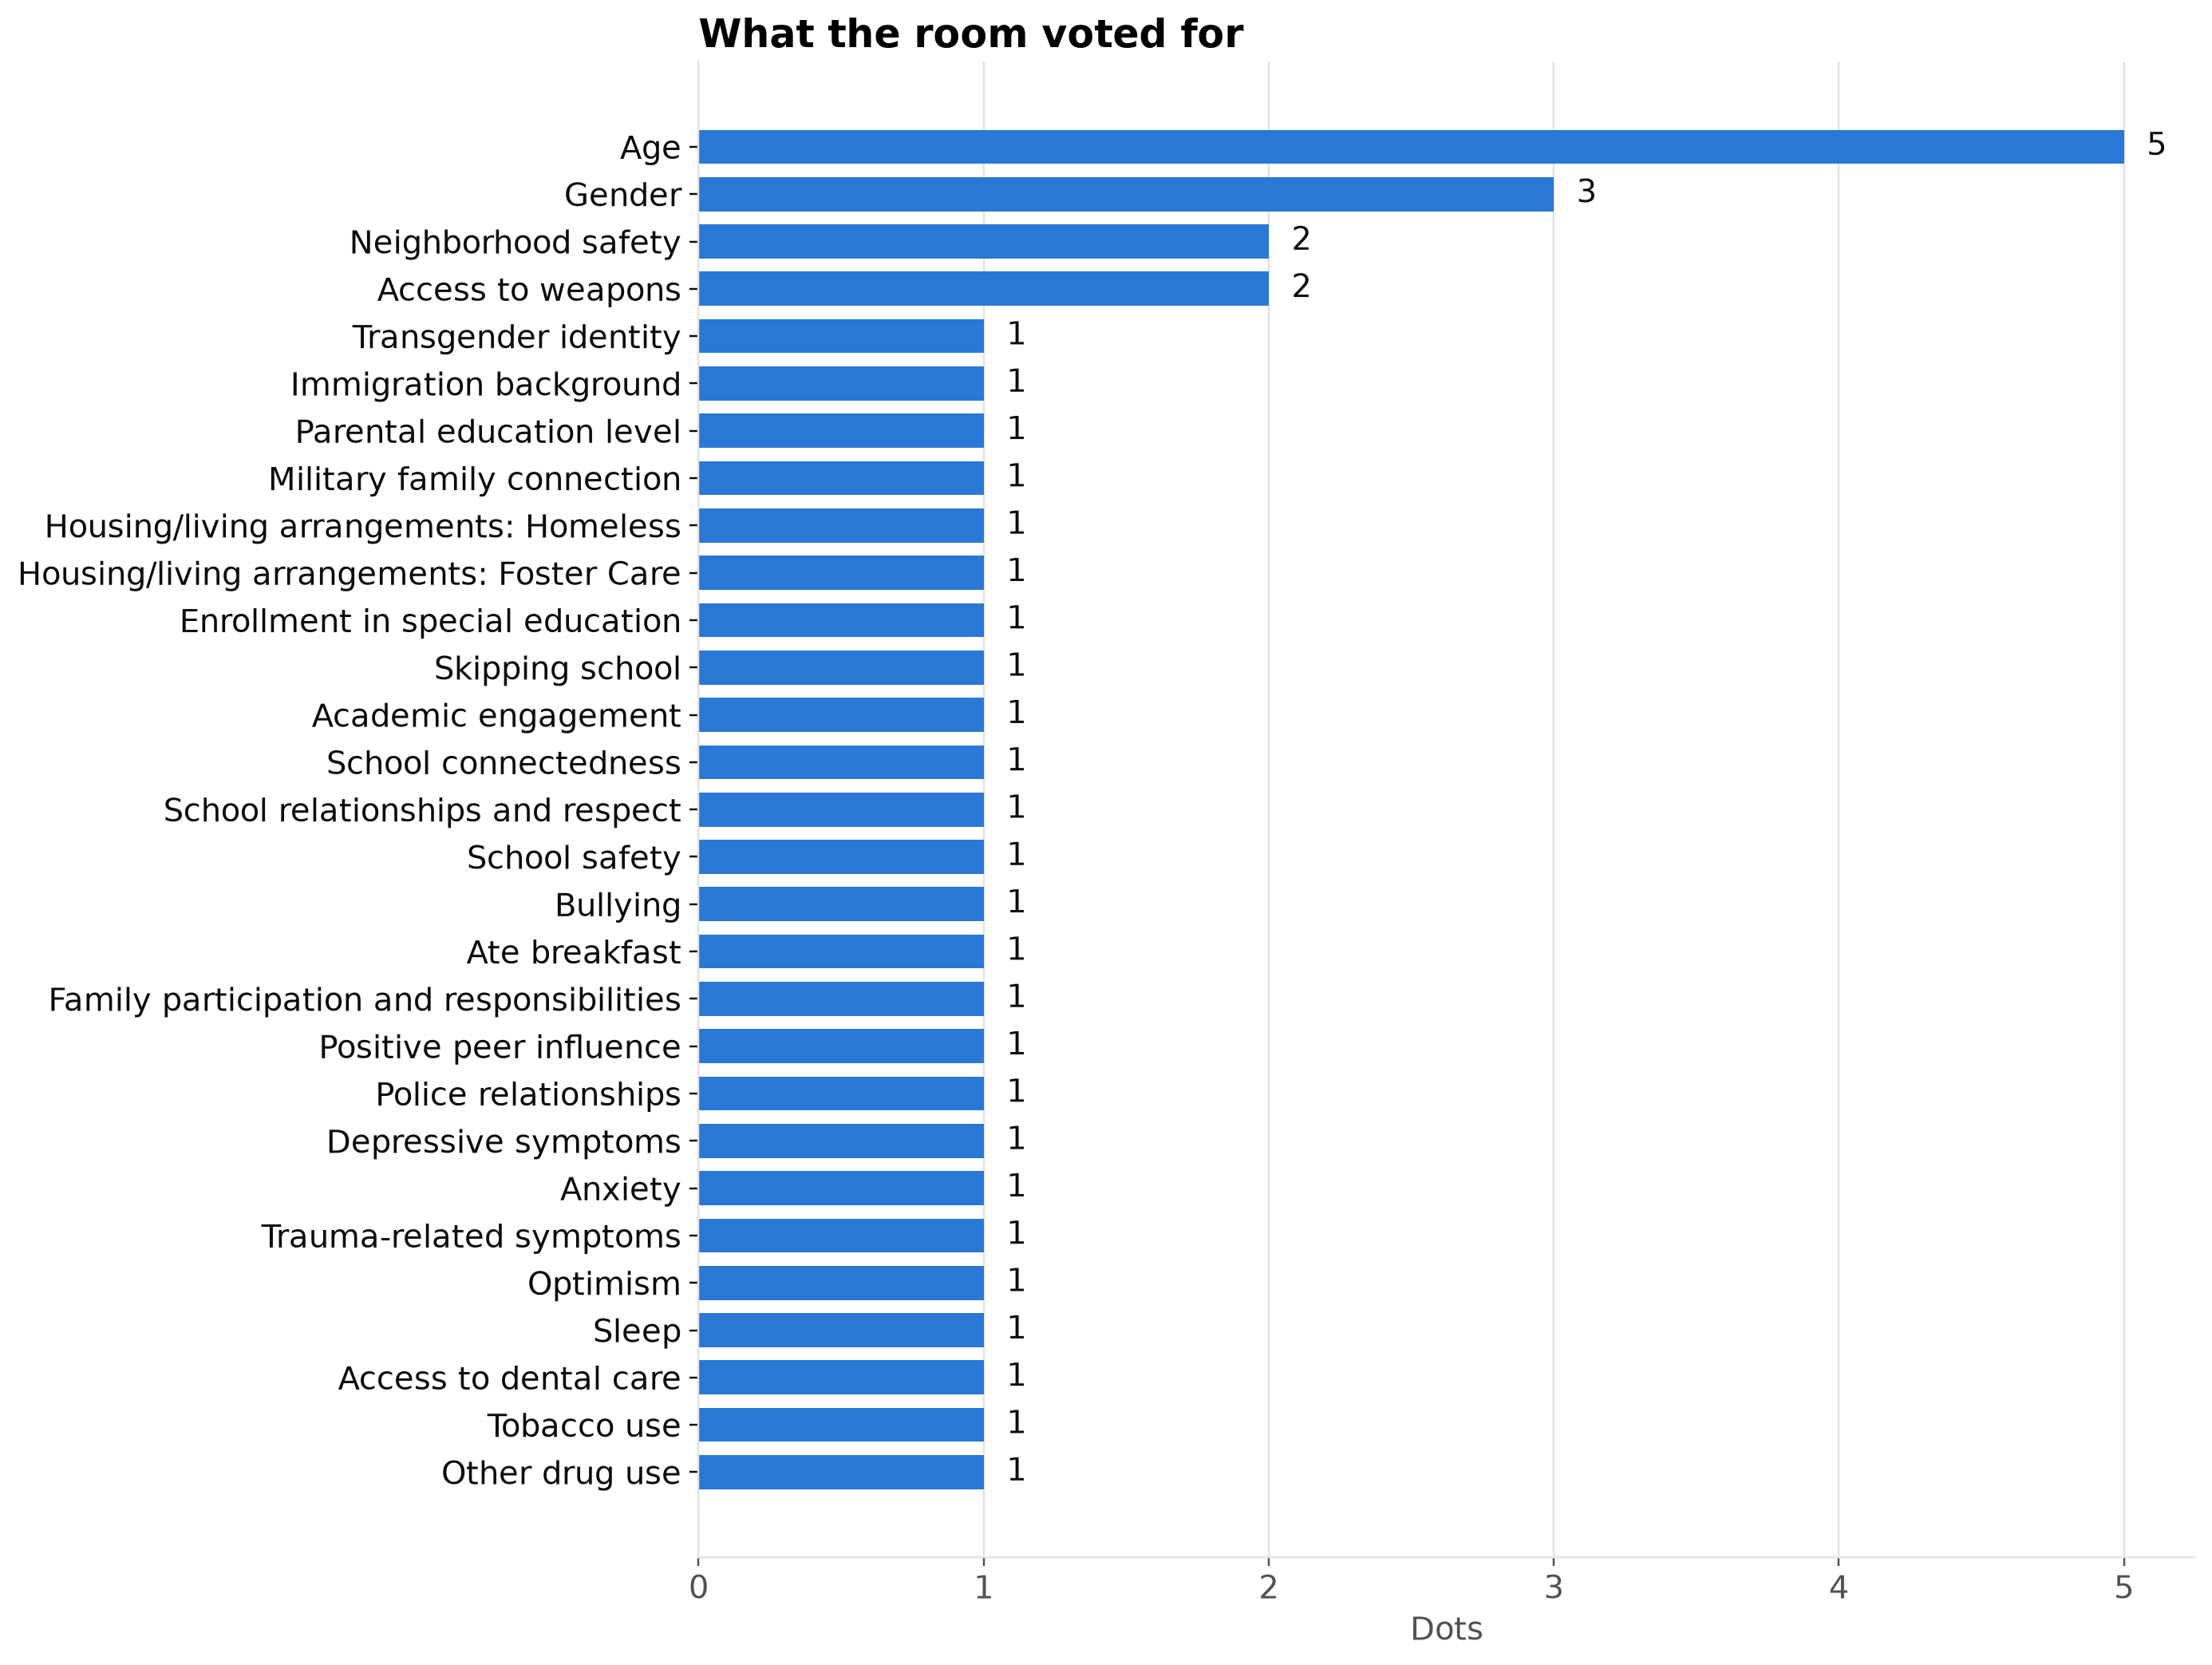

In [3]:
fig.votes_chart(ranked);

# Dataset

Real CHKS data are privacy-protected, and their sensitive items won't be run live in the room. This dataset is simulated, so the room can see the whole process with no real respondent involved. Real survey items cluster, so each fake respondent gets five correlated underlying factors, and every item is a noisy reflection of one or more of them.

In [4]:
pd.DataFrame(sd.FACTOR_CORR,
             index=["Distress", "Victimization", "Substance", "Connectedness", "Adversity"],
             columns=["Distress", "Victimization", "Substance", "Connectedness", "Adversity"])

,Distress,Victimization,Substance,Connectedness,Adversity
Distress,1.00,0.40,0.25,-0.35,0.15
Victimization,0.40,1.00,0.35,-0.25,0.15
Substance,0.25,0.35,1.00,-0.20,0.15
Connectedness,-0.35,-0.25,-0.20,1.00,-0.15
Adversity,0.15,0.15,0.15,-0.15,1.00


## Data-generating Mechanisms

The full item settings are in [`synthetic_data.py`](synthetic_data.py). The random seed follows a stated rule, so this rebuilds the same dataset every time.

In [5]:
display(Markdown("```python\n" + inspect.getsource(sd.generate) + "```"))

```python
def generate(n_respondents: int = N_RESPONDENTS, seed: int = DEFAULT_SEED) -> pd.DataFrame:
    rng = np.random.default_rng(seed)
    item_ids = load_item_ids()
    unspecified = set(item_ids) - set(ITEM_SPECS) - {"age", "grade"}
    if unspecified:
        raise ValueError(f"No synthetic spec for item(s): {sorted(unspecified)}")

    latent = rng.multivariate_normal(np.zeros(len(FACTORS)), FACTOR_CORR, size=n_respondents)
    factors = {f: latent[:, i] for i, f in enumerate(FACTORS)}

    data: dict[str, np.ndarray] = {}
    # Demographics that shift the latent factors come first.
    for item_id in ("gender", "transgender", "lgb"):
        (_, p), _ = ITEM_SPECS[item_id]
        data[item_id] = (rng.random(n_respondents) < p).astype(int)
    # Minority stress and internalizing differences (directions from the
    # literature; sizes are demo settings).
    factors["D"] = factors["D"] + 0.35 * data["lgb"] + 0.40 * data["transgender"] + 0.15 * data["gender"]
    factors["V"] = factors["V"] + 0.30 * data["lgb"] + 0.35 * data["transgender"]

    grade = rng.choice([9, 10, 11, 12], size=n_respondents, p=[0.27, 0.26, 0.24, 0.23])
    data["grade"] = grade
    data["age"] = np.clip(grade + 5 + rng.choice([0, 0, 0, 1, -1], size=n_respondents), 13, 18)

    for item_id in item_ids:
        if item_id in data:
            continue
        (kind, spec), loadings = ITEM_SPECS[item_id]
        x = _indicator(factors, loadings, rng, n_respondents)
        probs = [1 - spec, spec] if kind == "binary" else spec
        data[item_id] = _cut(x, probs)

    df = pd.DataFrame({item_id: data[item_id] for item_id in item_ids})

    lin = sum(w * factors[f] for f, w in SI_LATENT_EFFECTS.items())
    lin = lin + sum(w * df[item] for item, w in SI_DIRECT_EFFECTS.items())
    lin = np.asarray(lin, dtype=float)
    # Choose the intercept so expected prevalence matches IWFP's 16.8%.
    lo, hi = -10.0, 10.0
    for _ in range(60):
        mid = (lo + hi) / 2
        if (1 / (1 + np.exp(-(mid + lin)))).mean() > SI_PREVALENCE:
            hi = mid
        else:
            lo = mid
    p_si = 1 / (1 + np.exp(-(lo + lin)))
    df[OUTCOME_ITEM] = rng.binomial(1, p_si)
    return df
```

In [6]:
df = sd.generate()
print(f"{len(df):,} synthetic respondents, {df.shape[1] - 1} items plus the outcome")
df.head()

2,609 synthetic respondents, 84 items plus the outcome


,age,grade,race,gender,transgender,lgb,immigration_background,language,parental_education,military_family,...,screen_time,body_image,tobacco_use,vaping,alcohol_use,cannabis_use,other_drug_use,substance_risk_perceptions,substance_access,si
0,14,9,0,1,0,0,0,1,0,1,...,4,0,0,0,0,0,0,3,0,0
1,16,11,1,0,0,1,0,0,1,0,...,2,3,0,0,0,1,0,0,3,0
2,16,10,0,1,0,0,0,0,0,0,...,4,0,0,1,0,0,0,0,2,0
3,14,9,0,0,0,1,0,0,4,0,...,4,1,0,0,0,0,0,3,1,0
4,17,12,1,0,0,0,0,0,0,0,...,2,0,0,0,1,0,0,0,3,0


## How close is our simulated data to the published sample?

These totals are what the simulation was calibrated to. Matching them says nothing about whether any individual-level pattern is real.

In [7]:
pd.DataFrame(
    [{"Characteristic": name, "Published IWFP (%)": pct, "Synthetic (%)": round(df[col].mean() * 100, 2)}
     for name, col, pct in iwfp.TABLE_1]
)

,Characteristic,Published IWFP (%),Synthetic (%)
0,Past-year suicidal ideation,16.80,16.98
1,Female,50.60,50.48
2,Transgender,2.95,2.76
3,Sexual minority,17.00,16.75
4,Depressive symptoms,40.00,40.02
5,Foster care,0.34,0.34
6,Homeless,2.53,2.53
7,Ate breakfast,55.00,55.00


# Binary Variable Outcomes

## Suicidal Ideation

In the published study, this is the CHKS item on seriously considering suicide in the past 12 months. Here it is simulated, and it isn't on the voting board because it's what the model predicts.

In [8]:
pd.DataFrame({"Respondents": df["si"].value_counts().sort_index(),
              "Percent": (df["si"].value_counts(normalize=True).sort_index() * 100).round(1)}
             ).rename(index={0: "No SI", 1: "SI"})

,Respondents,Percent
si,,
No SI,2166,83.0
SI,443,17.0


# Predictor Variables

IWFP organized its 17 predictors by Indigenous Wholistic domain. This table shows how the room's votes line up with them, and whether the published model retained each one. The published study had no predictors in the Spiritual-Historical domain.

The other board items weren't in IWFP's model, so they have no domain here. Assigning them one is a decision for a community process, not this notebook.

In [9]:
vote_lookup = votes.set_index("item_id")["vote_count"]
domains = iwfp.PREDICTORS.assign(
    room_votes=lambda t: t["item_id"].map(vote_lookup).fillna(0).astype(int),
    in_room_model=lambda t: t["item_id"].isin(candidates).map({True: "Yes", False: "No"}),
    published_retained=lambda t: t["published_retained"].map({True: "Yes", False: "No"}),
)[["domain", "predictor", "room_votes", "in_room_model", "published_retained"]]
domains.columns = ["Domain", "IWFP predictor", "Room's dots", "In room's model", "Retained in published model"]
overlap = iwfp.PREDICTORS["item_id"].isin(candidates).sum()
print(f"The room chose {overlap} of IWFP's 17 predictors, plus {len(candidates) - overlap} that IWFP didn't include.")
domains

The room chose 10 of IWFP's 17 predictors, plus 19 that IWFP didn't include.


,Domain,IWFP predictor,Room's dots,In room's model,Retained in published model
0,Individual,Gender,3,Yes,No
1,Individual,Gender minority status,1,Yes,Yes
2,Individual,Sexual minority status,0,No,Yes
3,Individual,Academic performance,0,No,No
4,Individual,Lifetime alcohol use,0,No,Yes
5,Individual,Lifetime cigarette use,1,Yes,No
6,Individual,Lifetime vape use,0,No,Yes
7,Individual,Lifetime cannabis use,0,No,Yes
8,Individual,Lifetime other drug use,1,Yes,No
9,Emotional-Social,Foster care placement,1,Yes,No


# Analysis

## Fit the Model

LASSO logistic regression on standardized items, so odds ratios are per 1 standard deviation.

**Differences from `primary_analysis.do`:** the published model used Stata's `lasso logit, selection(cv)`. This one uses the one-standard-error rule, a stricter penalty, because tuning for best AUC alone let noise items survive with small effects. It also adds a bootstrap check. An item counts as a finding only if it's kept, its odds ratio is outside 0.98 to 1.02, and it's kept in at least 70 of 100 resamples.

In [10]:
result = pl.run_lasso(df, candidates)
print(f"Kept {len(result['selected_features'])} of {len(candidates)} candidates. "
      f"Nested cross-validated AUC: {result['cv_auc_mean']:.3f} (+/- {result['cv_auc_std']:.3f})")

Kept 9 of 29 candidates. Nested cross-validated AUC: 0.886 (+/- 0.016)


**In plain terms:** how simple can the model get before it gets worse? Moving right, the penalty gets stronger and fewer items stay in. The dashed line is the setting we chose.

**Go further:** the penalty is a choice made by the researcher. A different, defensible setting would keep a different list. Ask who made the choice and who it affects.

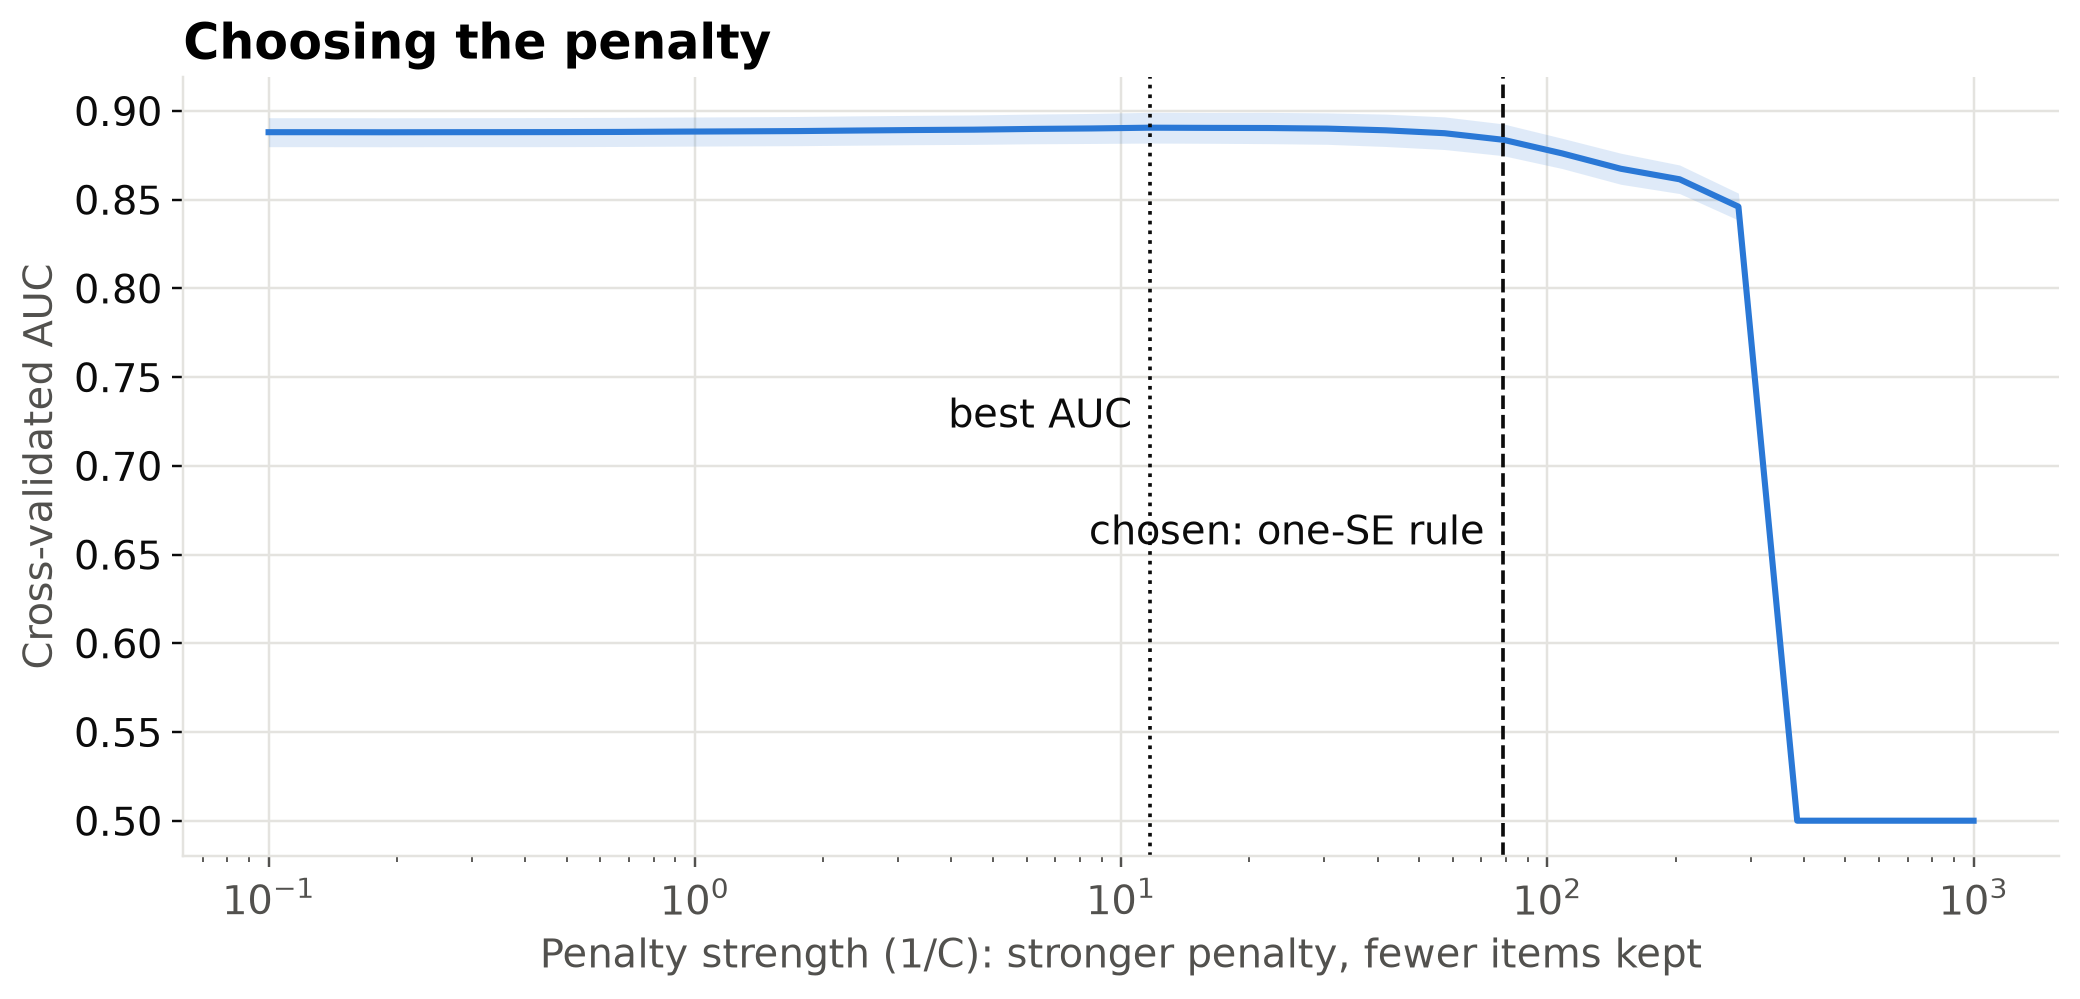

In [11]:
curve = pl.cv_curve(df, candidates)
fig.cv_chart(curve);

**In plain terms:** each line is one item. Raising the bar pushes every line toward zero. Items still away from zero at the dashed line are the ones the model kept.

**Go further:** compare a line's height on the left with its height at the dashed line. The penalty shrinks these numbers on purpose, so the odds ratios below are smaller than an unpenalized model would give.

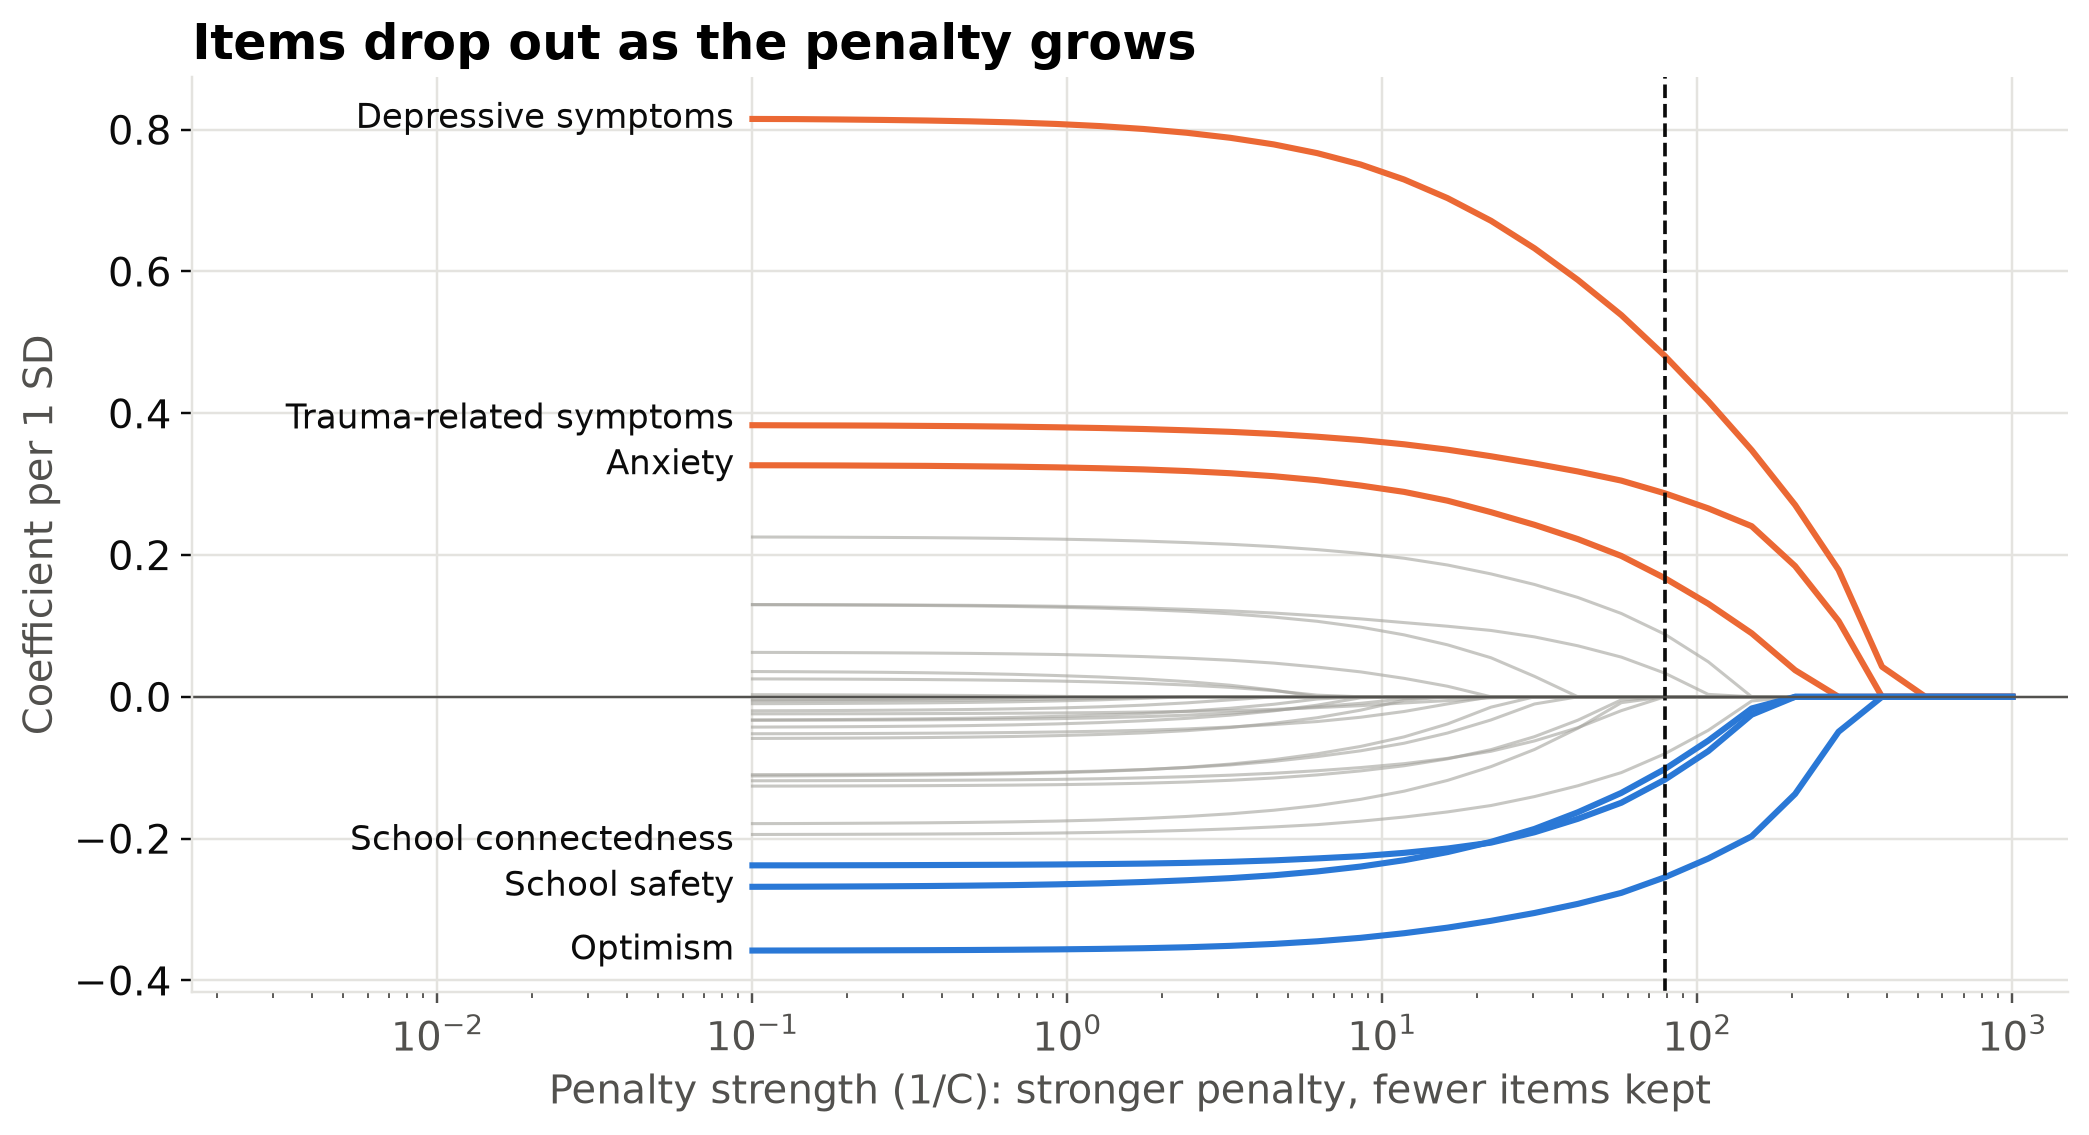

In [12]:
fig.path_chart(pl.coefficient_path(df, candidates), curve, labels);

## Coefficients

The equivalent of `lassocoef, display(coef, standardized)`.

In [13]:
coef_table = pd.DataFrame([
    {"Item": labels.get(f, f),
     "Dots": int(ranked.set_index("item_id").loc[f, "vote_count"]),
     "Odds ratio per SD": result["odds_ratios"][f] if f in result["selected_features"] else None,
     "Kept in resamples": f"{result['stability'][f]:.0%}",
     "Result": pl.classify(result, f)}
    for f in candidates
])
order = {"higher risk": 0, "protective": 1, "weak or unstable": 2, "dropped": 3}
coef_table = coef_table.sort_values(["Result", "Odds ratio per SD"], key=lambda c: c.map(order) if c.name == "Result" else c,
                                    ascending=[True, False], na_position="last").reset_index(drop=True)
coef_table

,Item,Dots,Odds ratio per SD,Kept in resamples,Result
0,Depressive symptoms,1,1.617,100%,higher risk
1,Trauma-related symptoms,1,1.333,100%,higher risk
2,Anxiety,1,1.182,100%,higher risk
3,Bullying,1,1.092,93%,higher risk
4,Skipping school,1,1.034,71%,higher risk
5,School relationships and respect,1,0.923,90%,protective
6,School safety,1,0.903,99%,protective
7,School connectedness,1,0.890,96%,protective
8,Optimism,1,0.775,100%,protective
9,Age,5,NaN,0%,dropped


**In plain terms:** to the right of 1 goes with more risk, and to the left goes with less. Longer lines are stronger links.

**Go further:** an odds ratio of 1.5 means 50% higher *odds* per 1 standard deviation, holding the other kept items fixed. It doesn't mean 50% higher risk, and these estimates have no confidence intervals. For a yes/no item, 1 standard deviation is smaller than the full step from no to yes, so these numbers aren't directly comparable with Table 2 in the paper. Ask: how many times what, for whom, compared to what?

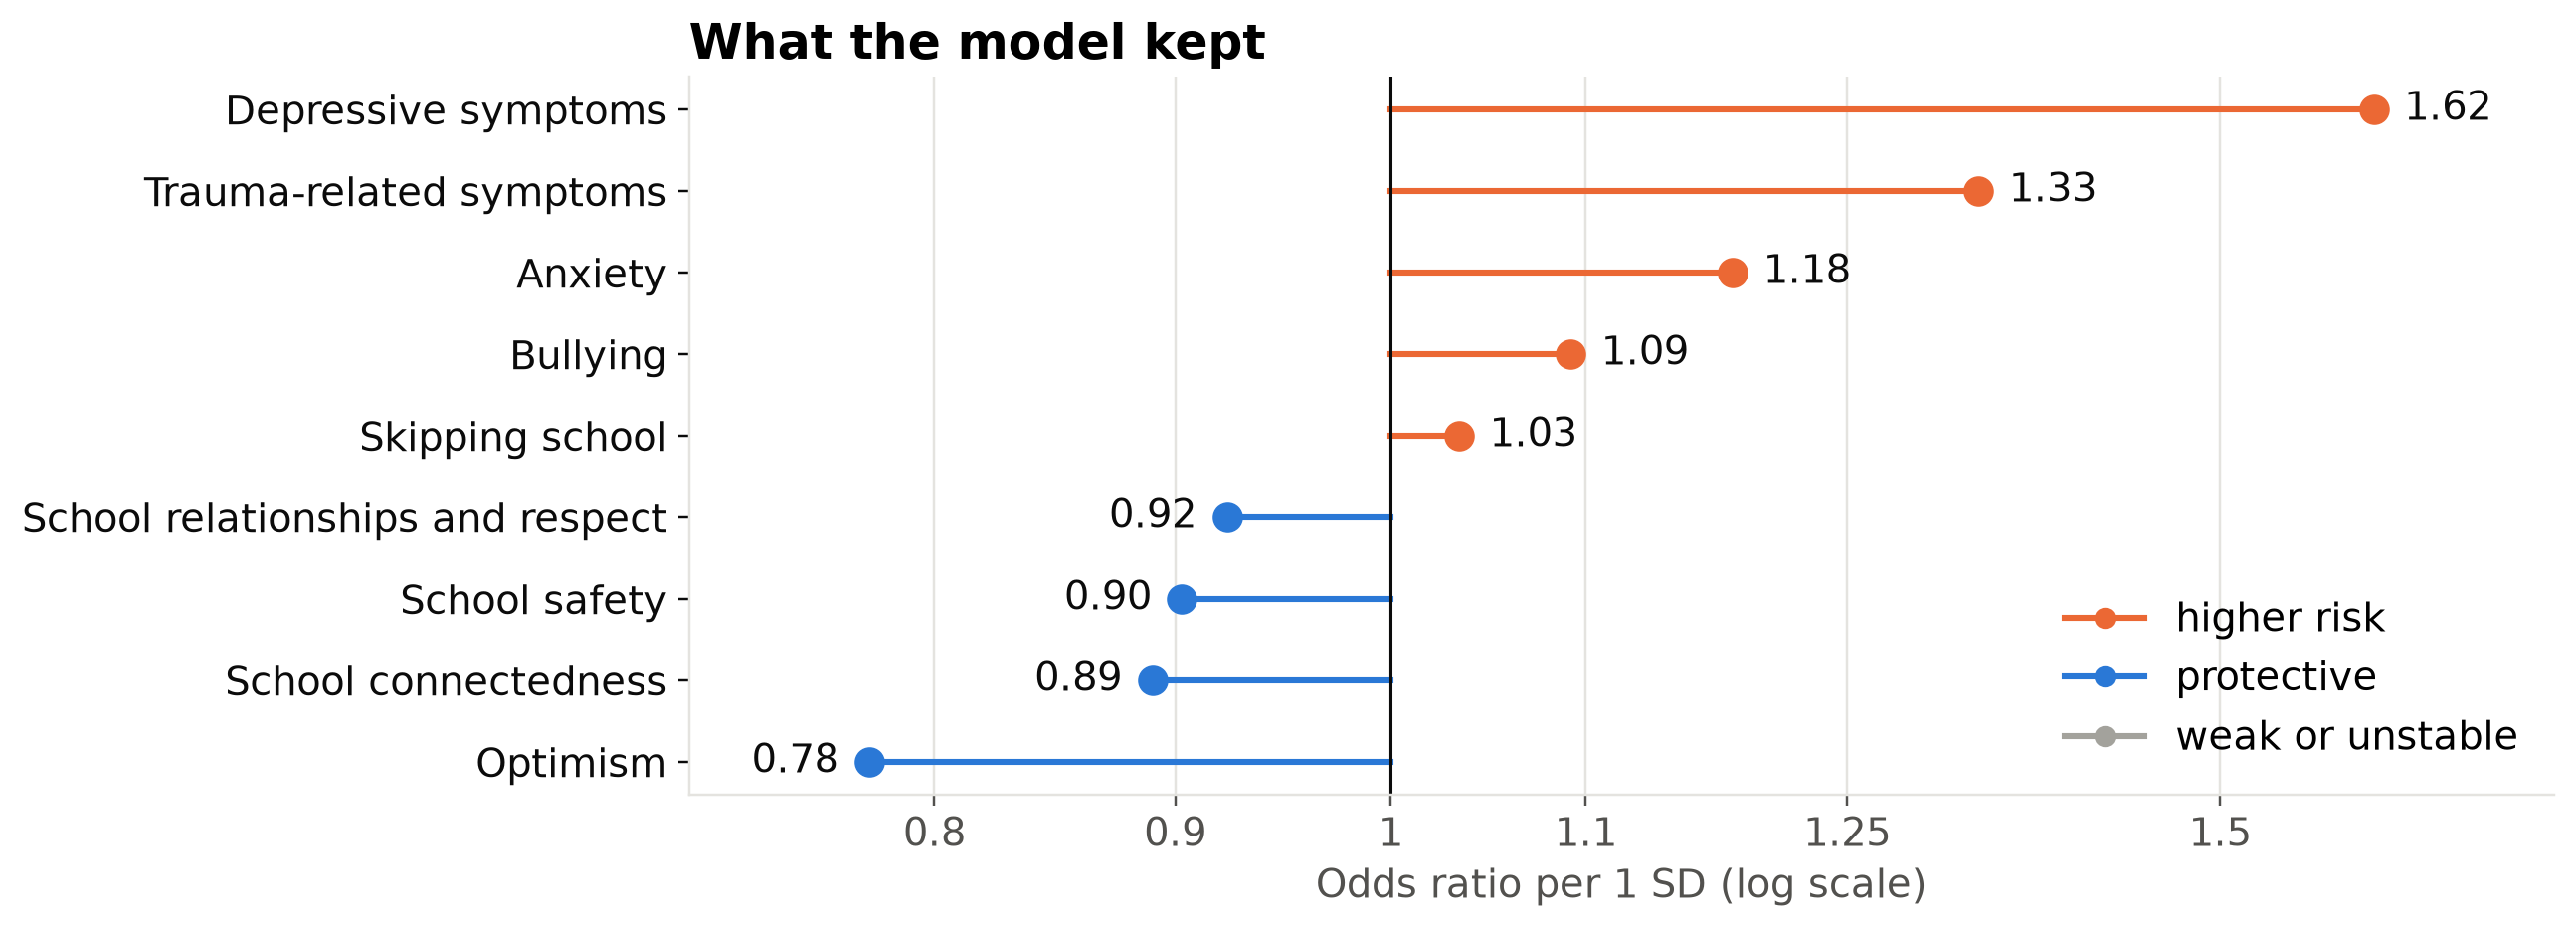

In [14]:
if result["selected_features"]:
    fig.odds_chart(result, labels, pl.classify);

**In plain terms:** if we reshuffled the group 100 times, would the model keep the same items? Colored bars count as findings.

**Go further:** stability only tests this sample, so it can't show that a result holds in another community. Similar items also compete, so one can look weak because another carried its signal. A dropped item isn't an unimportant one either. In this simulation, gender and sexual minority status raise distress and victimization, so once those items are in the model, the identity items have little left to add.

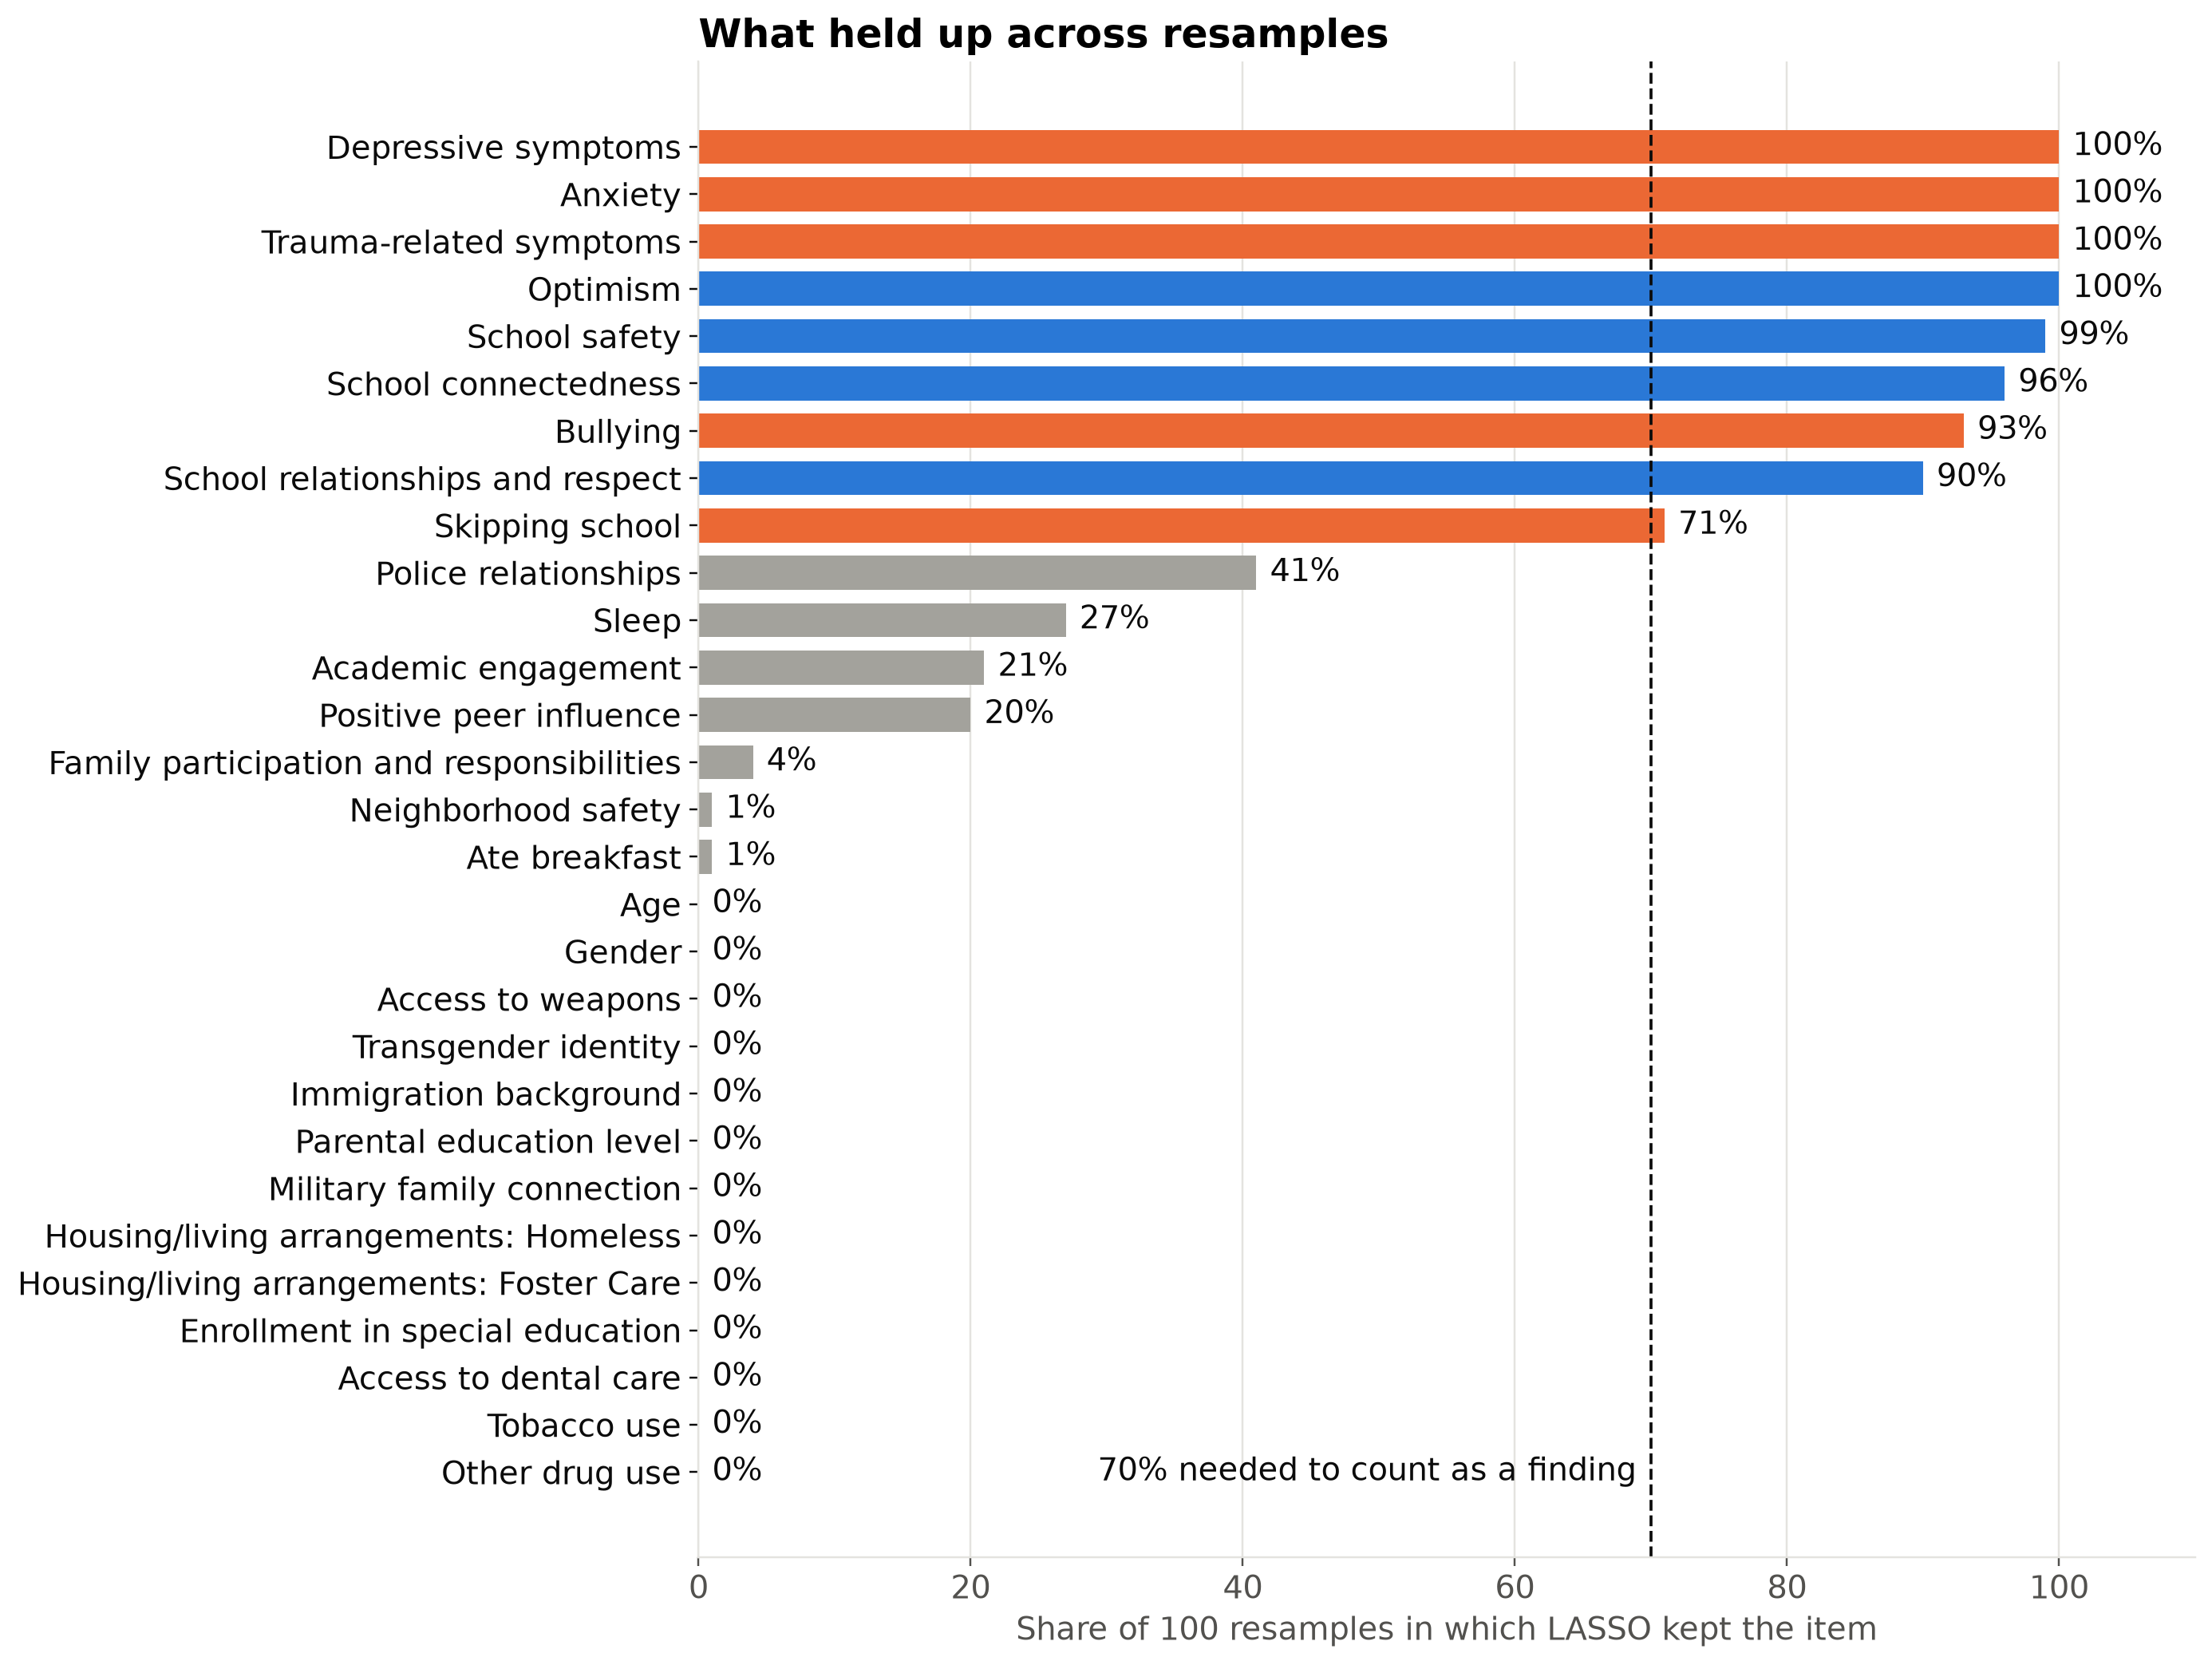

In [15]:
fig.stability_chart(result, labels, pl.classify);

## What the room valued and what held up

The room's top-voted items next to what the model did with them, calculated from this run.

In [16]:
findings = [f for f in candidates if pl.classify(result, f) in ("higher risk", "protective")]
close_calls = [labels.get(f, f) for f in findings
               if result["stability"][f] < 0.8 or abs(np.log(result["odds_ratios"][f])) < 0.05]
top_by_dots = coef_table.sort_values("Dots", ascending=False, kind="stable").head(5)

print(f"{len(findings)} of {len(candidates)} voted items count as findings.")
print(f"Close calls (kept in under 80% of resamples, or odds ratio within about 0.95 to 1.05): "
      f"{', '.join(close_calls) or 'none'}")
top_by_dots[["Item", "Dots", "Kept in resamples", "Result"]].reset_index(drop=True)

9 of 29 voted items count as findings.
Close calls (kept in under 80% of resamples, or odds ratio within about 0.95 to 1.05): Skipping school


,Item,Dots,Kept in resamples,Result
0,Age,5,0%,dropped
1,Gender,3,0%,dropped
2,Neighborhood safety,2,1%,dropped
3,Access to weapons,2,0%,dropped
4,Depressive symptoms,1,100%,higher risk


**Go further:** what did the model drop that you would still act on? For a close call, ask whether you'd still tell the same story if it had landed just under the line.

## Calibration

Do predicted risks match observed rates? The published study used a GiViTI calibration belt (`calibrationbelt`), which has no standard Python version. This chart shows the same question using groups of predicted risk, along with a logistic recalibration slope. It is a stand-in, not the same test. A slope above 1 means predictions are too moderate, which a strong penalty tends to produce.

Predictions here come from models that never saw the respondent they're scoring.

**In plain terms:** when the model says 20%, is it really about 20%? Each dot is a tenth of the sample. On the dashed line, the percentages are right. Below it they're too high, and above it they're too low.

**Go further:** the published calibration belt also found over-prediction at low risk, and community partners judged that acceptable because a false flag could still connect a student to support. That chart was real data, and this one is simulated, so treat this as a way of reasoning rather than evidence. Whether an error is acceptable depends on how the number will be used.

Recalibration slope 1.64, intercept 0.37 (perfect: 1 and 0)


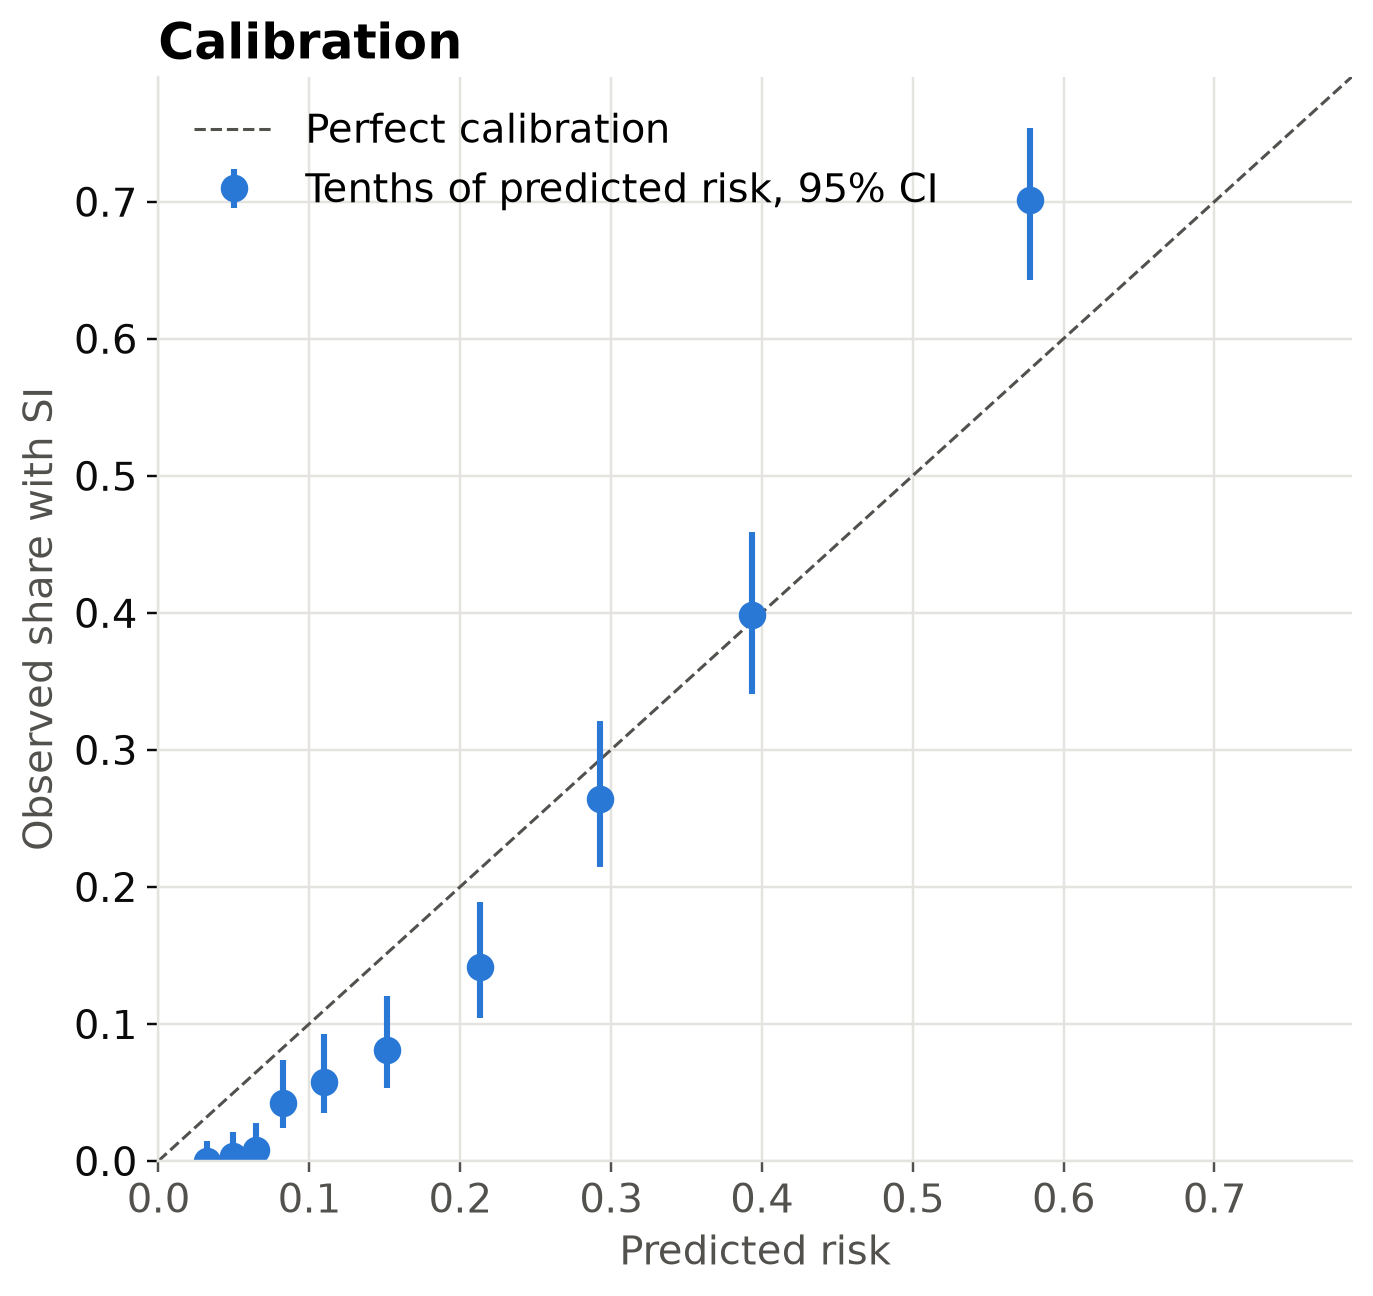

In [17]:
y = df["si"].to_numpy()
room_risk = pl.out_of_fold_risk(df, candidates)
slope = pl.calibration_slope(y, room_risk)
print(f"Recalibration slope {slope['slope']:.2f}, intercept {slope['intercept']:.2f} (perfect: 1 and 0)")
fig.calibration_chart(pl.calibration_table(y, room_risk));

## Validation

10-fold cross-validation with seed 1533, as in `cvauroc`, plus the Brier score. The interval is a percentile bootstrap, while the paper reports a bias-corrected one.

**In plain terms:** can the model tell the two groups apart? An AUC of 0.5 is a coin flip and 1 is perfect. Curves closer to the top left are better.

**Go further:** AUC asks whether people are in the right order. Calibration asks whether the percentages are right. A model can do well on one and poorly on the other. Ordering may be enough to decide who to reach first, but telling someone their risk needs correct percentages.

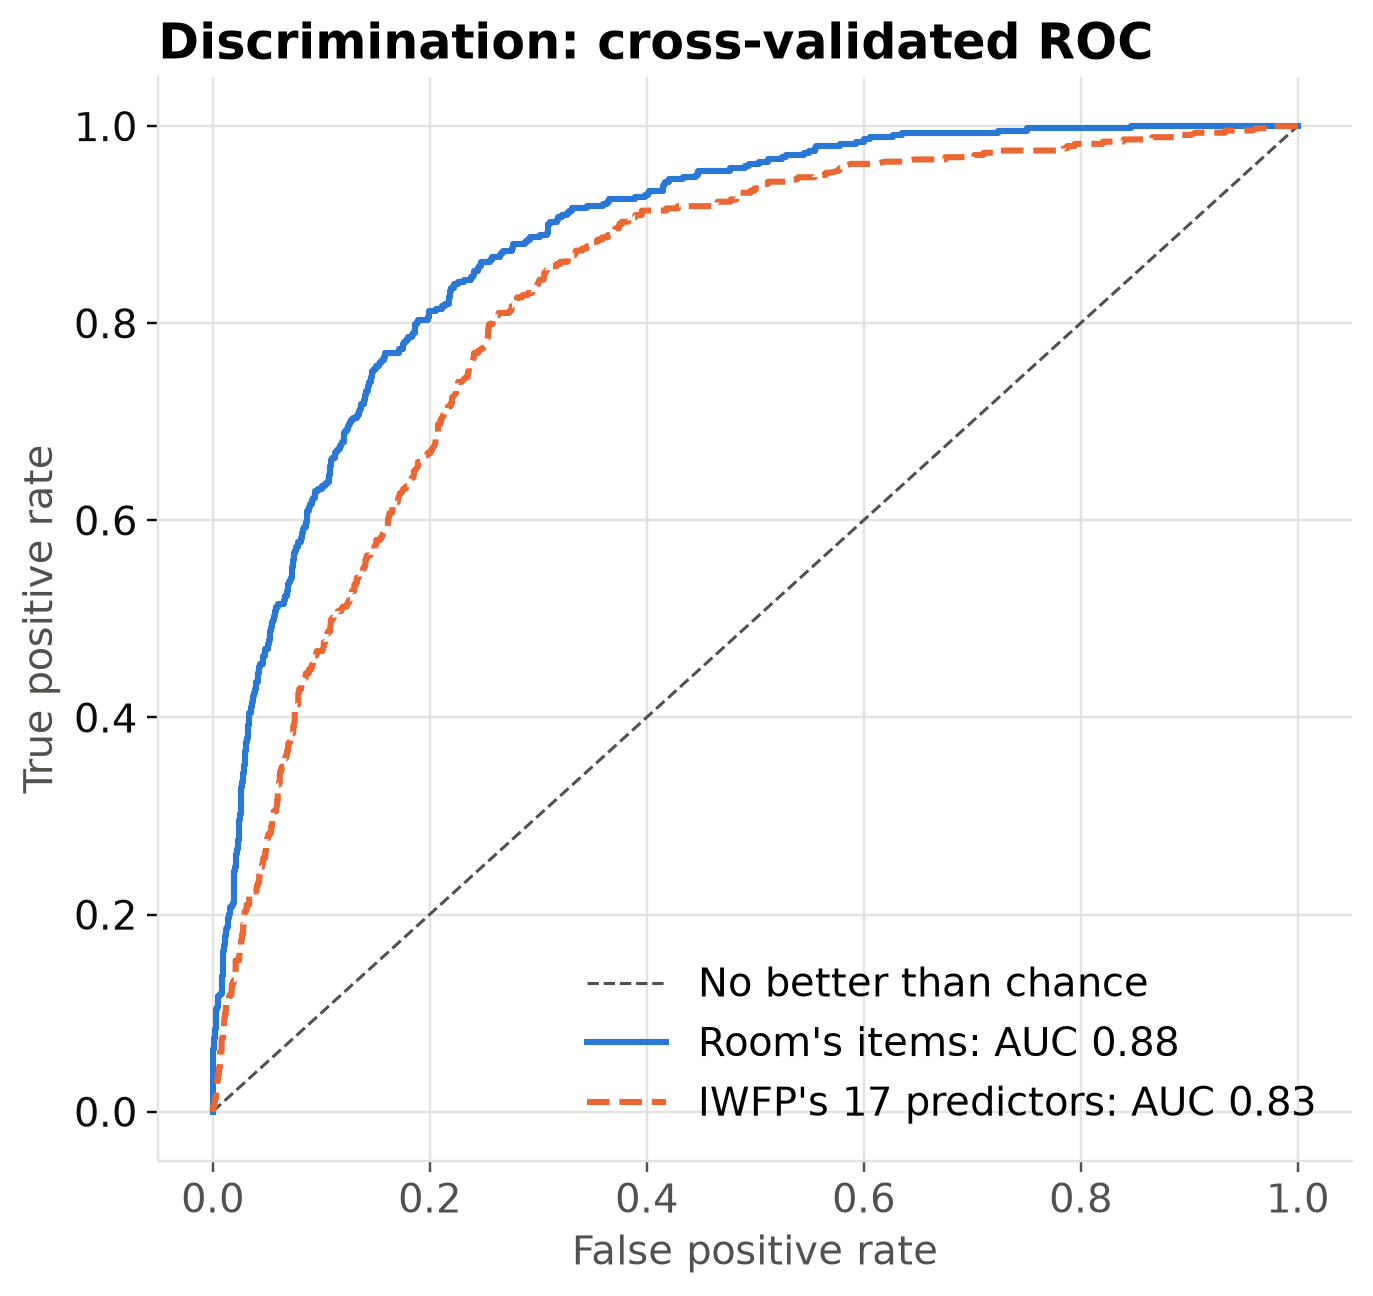

In [18]:
iwfp_items = iwfp.PREDICTORS["item_id"].tolist()
iwfp_result = pl.run_lasso(df, iwfp_items)
iwfp_risk = pl.out_of_fold_risk(df, iwfp_items)
room_perf, iwfp_perf = pl.performance(y, room_risk), pl.performance(y, iwfp_risk)

fig.roc_chart(y, [("Room's items", room_risk, room_perf["auc"]),
                  ("IWFP's 17 predictors", iwfp_risk, iwfp_perf["auc"])]);

**In plain terms:** this shows where each group's scores land. The overlap is where mistakes happen.

**Go further:** each curve is scaled to the same area, but far more people did not report SI. The overlap holds more people without SI than it appears to.

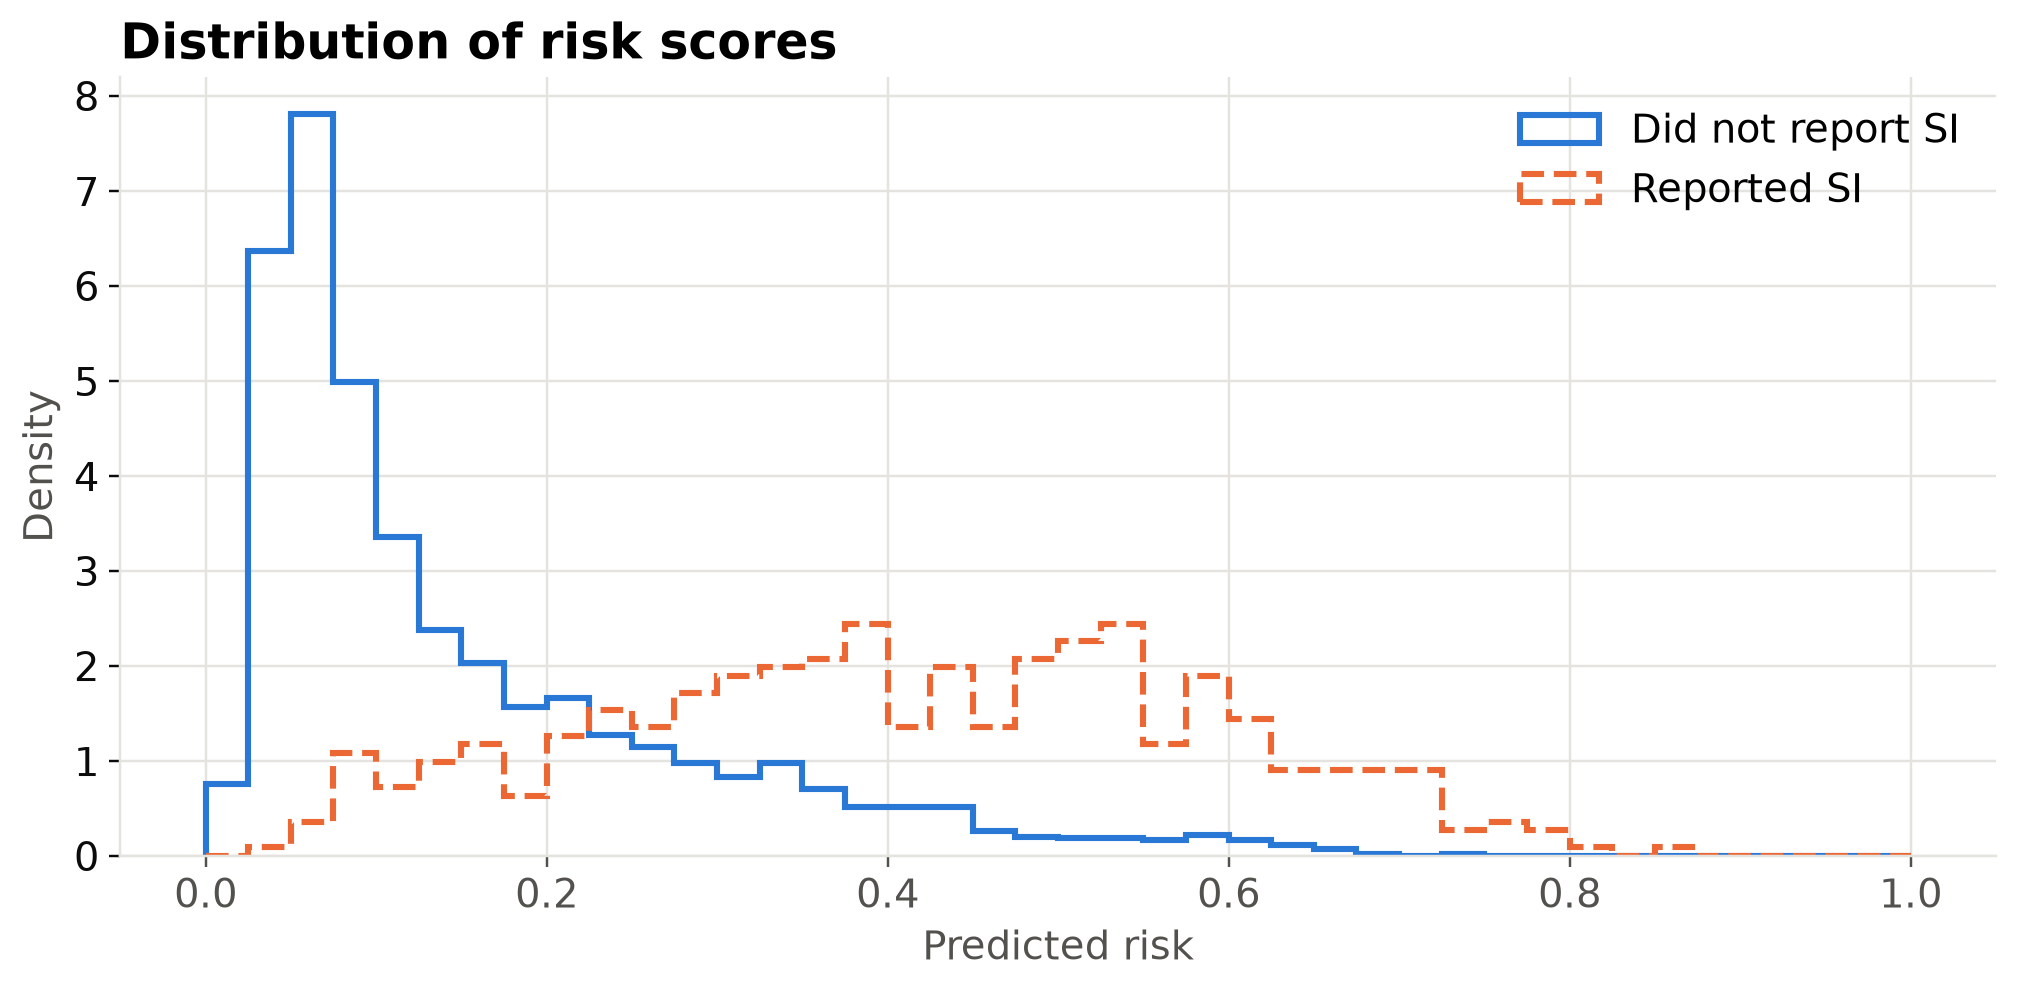

In [19]:
fig.risk_chart(y, room_risk);

## Turning accuracy into people

The same model, as outcomes for 100 people, at a cutoff that wrongly flags 20% of those without SI.

In [20]:
people = pl.per_100_people(y, room_risk, false_alarm=0.2)
flagged_total = round(people["flagged_with"]) + round(people["flagged_without"])
print(f"Of about {flagged_total} people flagged, about {people['flagged_with']:.0f} have SI.")
pd.DataFrame(
    {"Flagged": [round(people["flagged_with"]), round(people["flagged_without"])],
     "Not flagged": [round(people["missed_with"]), round(people["clear_without"])]},
    index=["Reported SI", "Did not report SI"],
)

Of about 31 people flagged, about 14 have SI.


,Flagged,Not flagged
Reported SI,14,3
Did not report SI,17,66


**Go further:** moving the cutoff trades one kind of mistake for the other, and no cutoff removes both. What happens to someone who is flagged, and to someone who is missed? Who should set this cutoff?

# The room's choices next to IWFP's

The first two columns use the same synthetic data, so they compare the predictor sets. The last column is the published model on real CHKS data, shown for reference. **A higher synthetic AUC doesn't mean the room found something the study missed**, because the simulation's settings shape which items predict well.

**How to read the table:** lower Brier scores are better, and always guessing the 17% base rate would score about 0.14. The synthetic models retain different numbers of predictors from the published model partly because this notebook uses a stricter penalty rule, and partly because the data are different.

**Go further:** a table like this can't show what the survey never asked. Whose knowledge is missing from it?

In [21]:
def describe(offered, retained, perf):
    return {
        "Predictors offered": offered,
        "Predictors retained": retained,
        "Cross-validated AUC (95% CI)": f"{perf['auc']:.2f} ({perf['auc_low']:.2f}, {perf['auc_high']:.2f})",
        "Brier score": f"{perf['brier']:.2f}",
        "Median predicted risk (IQR)": f"{perf['risk_median']:.1%} ({perf['risk_q1']:.1%} to {perf['risk_q3']:.1%})",
    }

pd.DataFrame({
    "Room's items, synthetic": describe(len(candidates), len(result["selected_features"]), room_perf),
    "IWFP's 17, synthetic": describe(17, len(iwfp_result["selected_features"]), iwfp_perf),
    "Published IWFP, real CHKS": describe(17, iwfp.PUBLISHED["predictors retained"], iwfp.PUBLISHED),
})

,"Room's items, synthetic","IWFP's 17, synthetic","Published IWFP, real CHKS"
Predictors offered,29,17,17
Predictors retained,9,6,10
Cross-validated AUC (95% CI),"0.88 (0.87, 0.90)","0.83 (0.81, 0.85)","0.87 (0.84, 0.88)"
Brier score,0.10,0.11,0.10
Median predicted risk (IQR),12.8% (6.5% to 29.2%),9.3% (6.6% to 30.9%),4.8% (2.6% to 26.8%)


# In plain terms

In [22]:
print(pl.format_report(result, labels).split("In plain terms", 1)[-1].split(":", 1)[-1].strip())

Risk factors:       Depressive symptoms, Trauma-related symptoms, Anxiety, Bullying, Skipping school
  Protective factors: Optimism, School connectedness, School safety, School relationships and respect
  The other 20 added little or nothing beyond these, or didn't hold up across resamples.


Questions for the room:

- **LASSO keeps what predicts best, not what matters most for prevention.** What did it drop that you would still act on?
- **Correlated items compete.** Support and connectedness items can split the same signal, so one can look unimportant only because another carried it.
- **What's missing from the board?** The published study had no Spiritual-Historical predictors because of what the survey asked.
- **Who chooses the variables in your own projects, and how could the community?**

## Questions to ask of any model

1. **How will this be used?** To decide who to reach first, or to tell someone their risk?
2. **How big is the effect, and in what units?** Check the size, the direction and what the scale means.
3. **Does it hold up?** Check it across resamples, and then in other settings if you can.
4. **What does it mean for people?** Count who gets flagged, who gets missed and what happens to each.
5. **Who made the choices?** That includes the variables, the penalty and the cutoff.
6. **What can't this data tell you?** Look for what was never asked, and who wasn't asked.

# Save this run

In [23]:
from datetime import datetime

stamp = datetime.now().strftime("%Y-%m-%d_%H%M%S")
os.makedirs("results", exist_ok=True)
coef_table.to_csv(f"results/{stamp}_{BOARD_ID}_model_results.csv", index=False)
print(f"Saved results/{stamp}_{BOARD_ID}_model_results.csv")

Saved results/2026-11-03_225923_nov4-rehearsal_model_results.csv
